# Classical Markowitz Portfolio Optimization

This notebook examines rolling minimum-variance, maximum-Sharpe, and target-volatility allocations for the core ETF universe. The saved allocations feed the realized out-of-sample return and final comparison modules.


## Methodology and constraints

Each rebalance date uses the preceding 60 monthly returns, ending at t-1. Expected returns are annualized arithmetic sample means. Covariance is estimated either from the annualized sample covariance matrix or with Ledoit-Wolf shrinkage.

Every portfolio is fully invested, long-only, unleveraged, and capped at 25% per ETF. Minimum variance minimizes portfolio variance. Maximum Sharpe uses a convex transformed tangency-portfolio problem with the configured annual risk-free rate. Target volatility maximizes expected return subject to a 10% annualized volatility ceiling. CVXPY attempts OSQP, then SCS, then ECOS when installed.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

TABLES = PROJECT_ROOT / 'outputs/tables'
FIGURES = PROJECT_ROOT / 'outputs/figures'
print('Project root:', PROJECT_ROOT)


Project root: .


## Sample versus Ledoit-Wolf rolling weights

In [2]:
weight_files = {
    ('min_variance', 'sample'): 'weights_min_variance_sample_60m.csv',
    ('min_variance', 'ledoit_wolf'): 'weights_min_variance_ledoit_60m.csv',
    ('max_sharpe', 'sample'): 'weights_max_sharpe_sample_60m.csv',
    ('max_sharpe', 'ledoit_wolf'): 'weights_max_sharpe_ledoit_60m.csv',
    ('target_volatility', 'sample'): 'weights_target_vol_sample_60m.csv',
    ('target_volatility', 'ledoit_wolf'): 'weights_target_vol_ledoit_60m.csv',
}
weights = {
    key: pd.read_csv(TABLES / filename, index_col='date', parse_dates=['date'])
    for key, filename in weight_files.items()
}
weights[('min_variance', 'sample')].head()

                     SPY       QQQ       IWM           MDY           EFA           EEM           VGK           EWJ           VPL   SHY   IEF           TLT       TIP           BWX           LQD           HYG           EMB           GLD           DBC       GSG           VNQ           RWX   BIL
date                                                                                                                                                                                                                                                                                                
2013-02-28  3.252599e-18  0.048689  0.008513  3.252599e-18  3.252657e-18  3.252624e-18  3.252650e-18  2.089131e-03  3.252674e-18  0.25  0.25  3.252550e-18  0.181657  3.252576e-18  3.252565e-18  3.252585e-18  3.252590e-18  3.252557e-18  3.252594e-18  0.009051  3.252641e-18  3.252653e-18  0.25
2013-03-31  1.485356e-17  0.044787  0.009315  1.485355e-17  1.485362e-17  1.485359e-17  1.485361e-17  1.931918e-03  1.485

In [3]:
summary = pd.read_csv(TABLES / 'markowitz_weight_summary.csv')
summary

            strategy covariance_method  average_number_of_positions  average_weight  maximum_weight  average_turnover
0       min_variance            sample                      7.25000        0.137931            0.25          0.019004
1       min_variance       ledoit_wolf                      9.30000        0.107527            0.25          0.017196
2         max_sharpe            sample                      5.58125        0.179171            0.25          0.074700
3         max_sharpe       ledoit_wolf                      6.31875        0.158259            0.25          0.066313
4  target_volatility            sample                      5.36875        0.186263            0.25          0.078927
5  target_volatility       ledoit_wolf                      5.30000        0.188679            0.25          0.074553

`average_number_of_positions` counts weights above 0.01%. `average_weight` is calculated across those active positions. Turnover is one half of the absolute month-to-month change in target weights, excluding the first allocation.

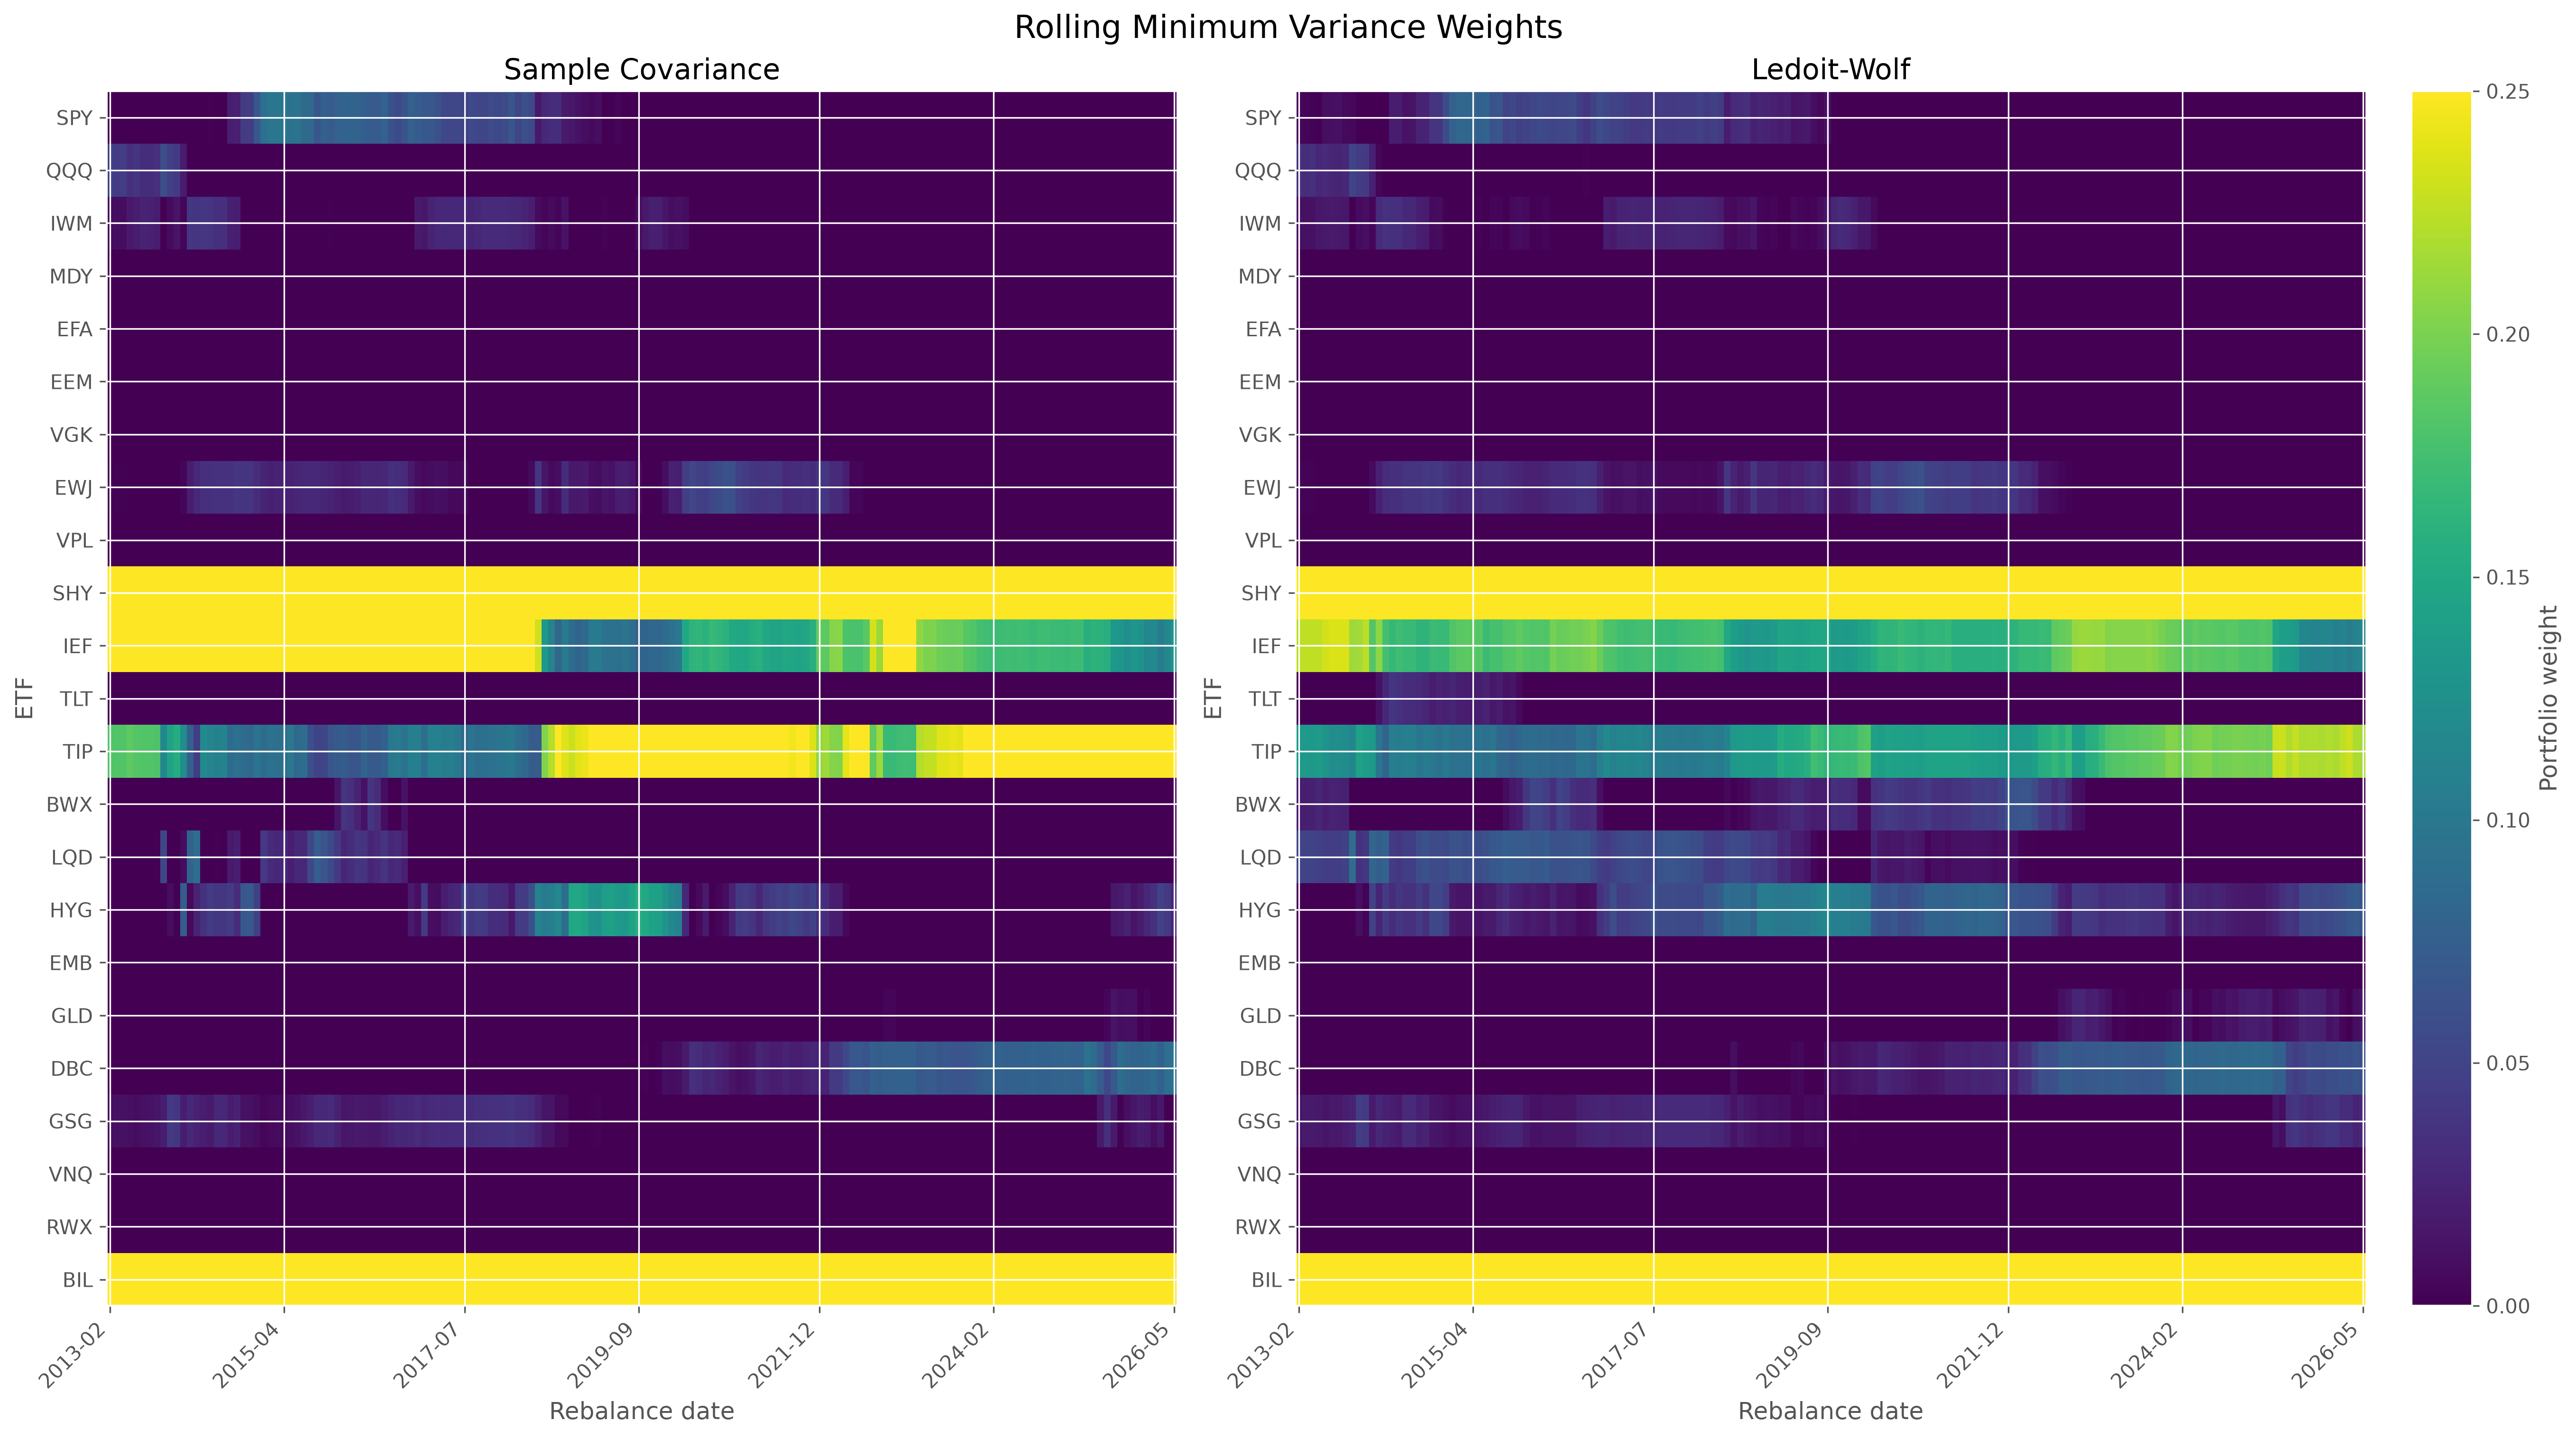

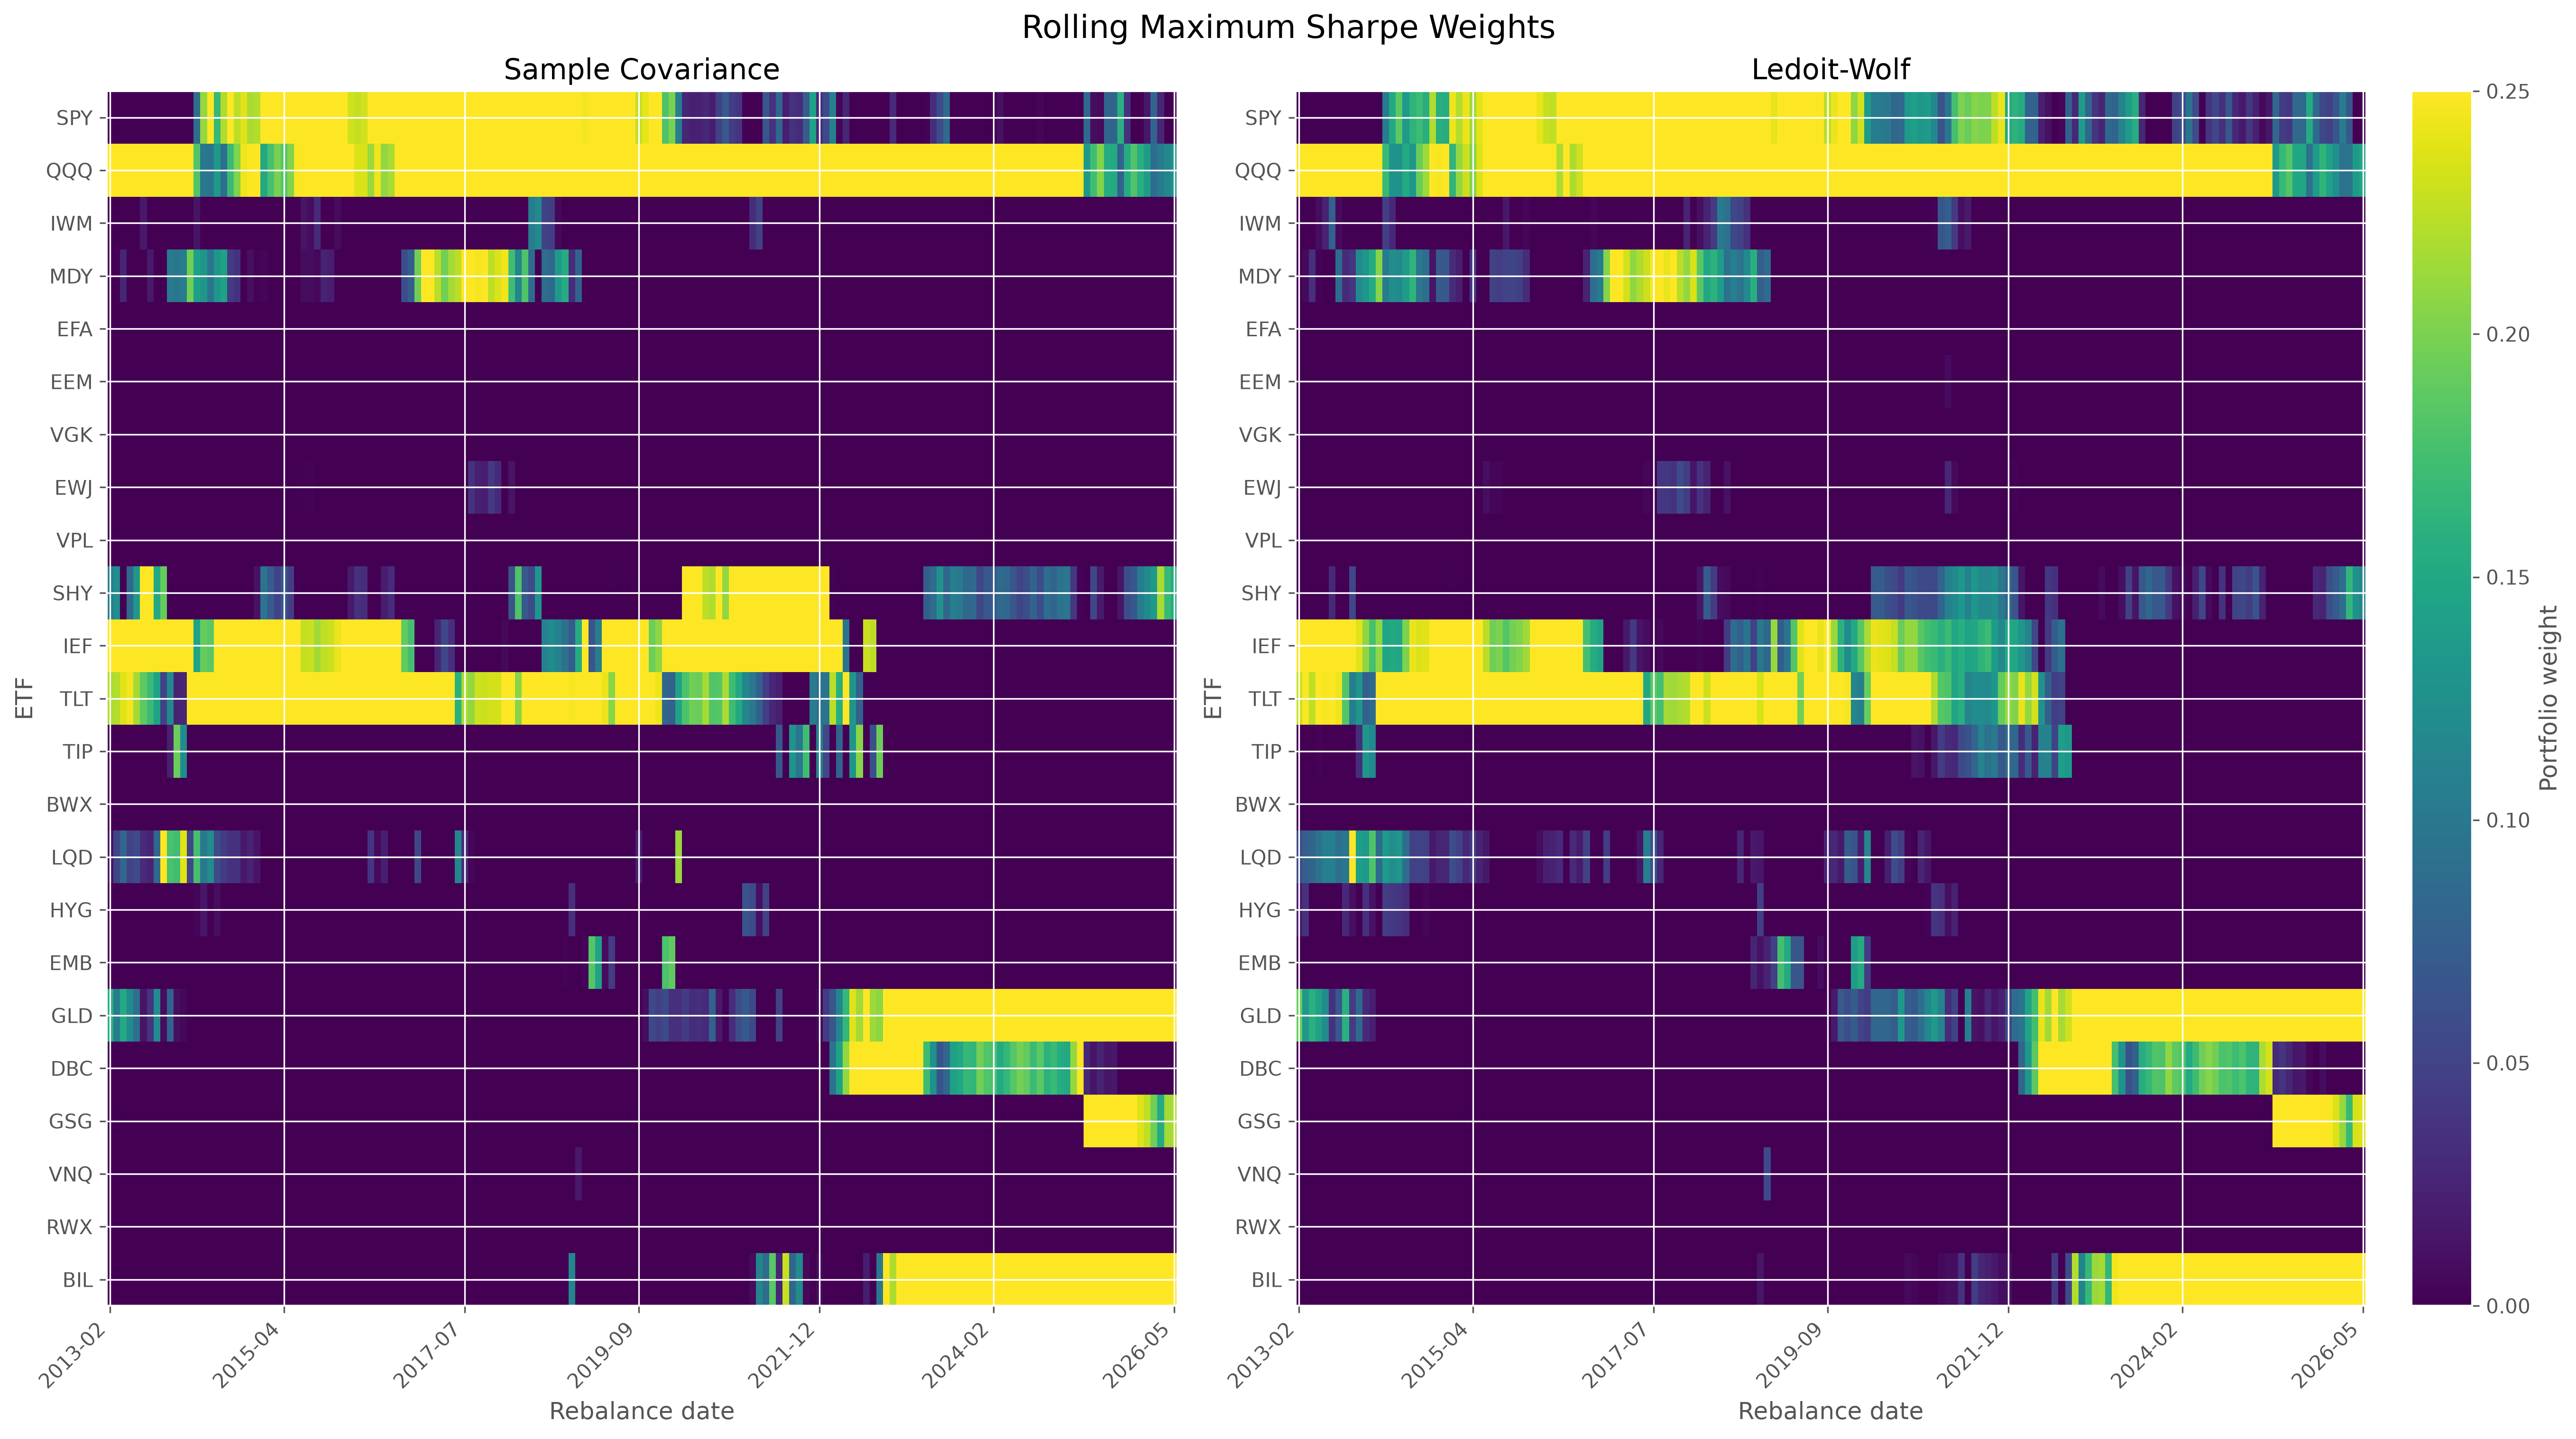

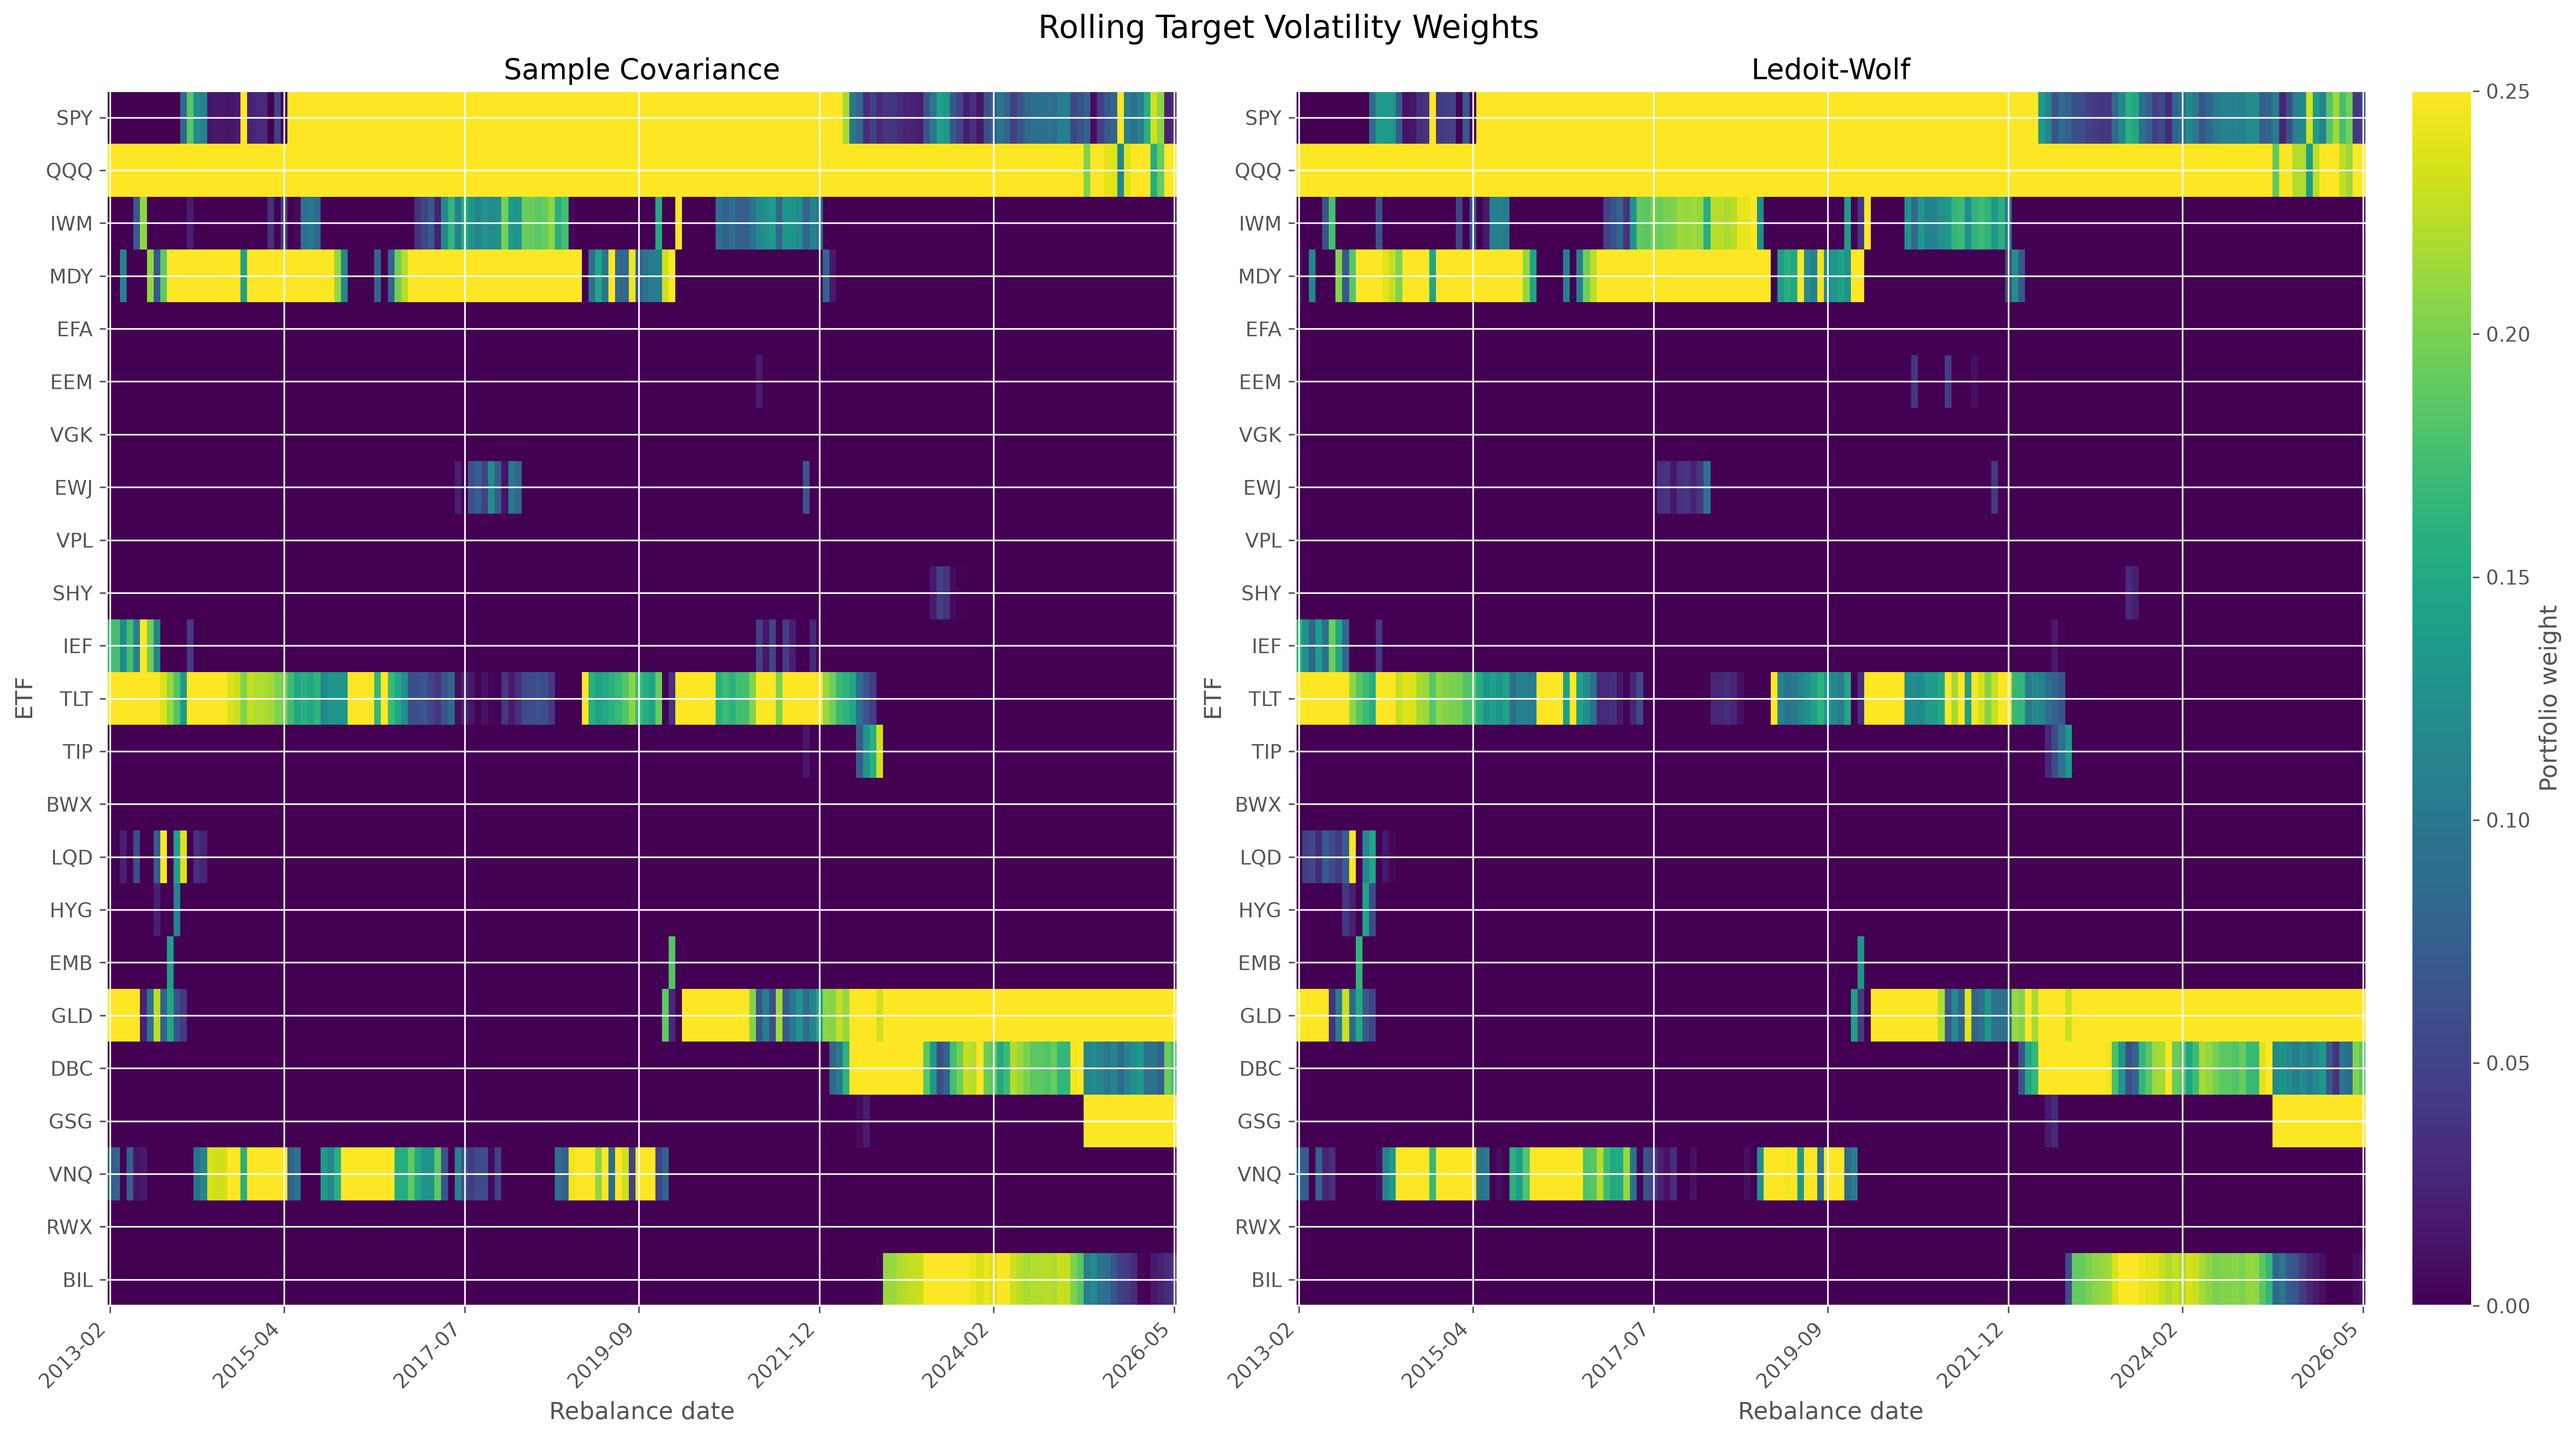

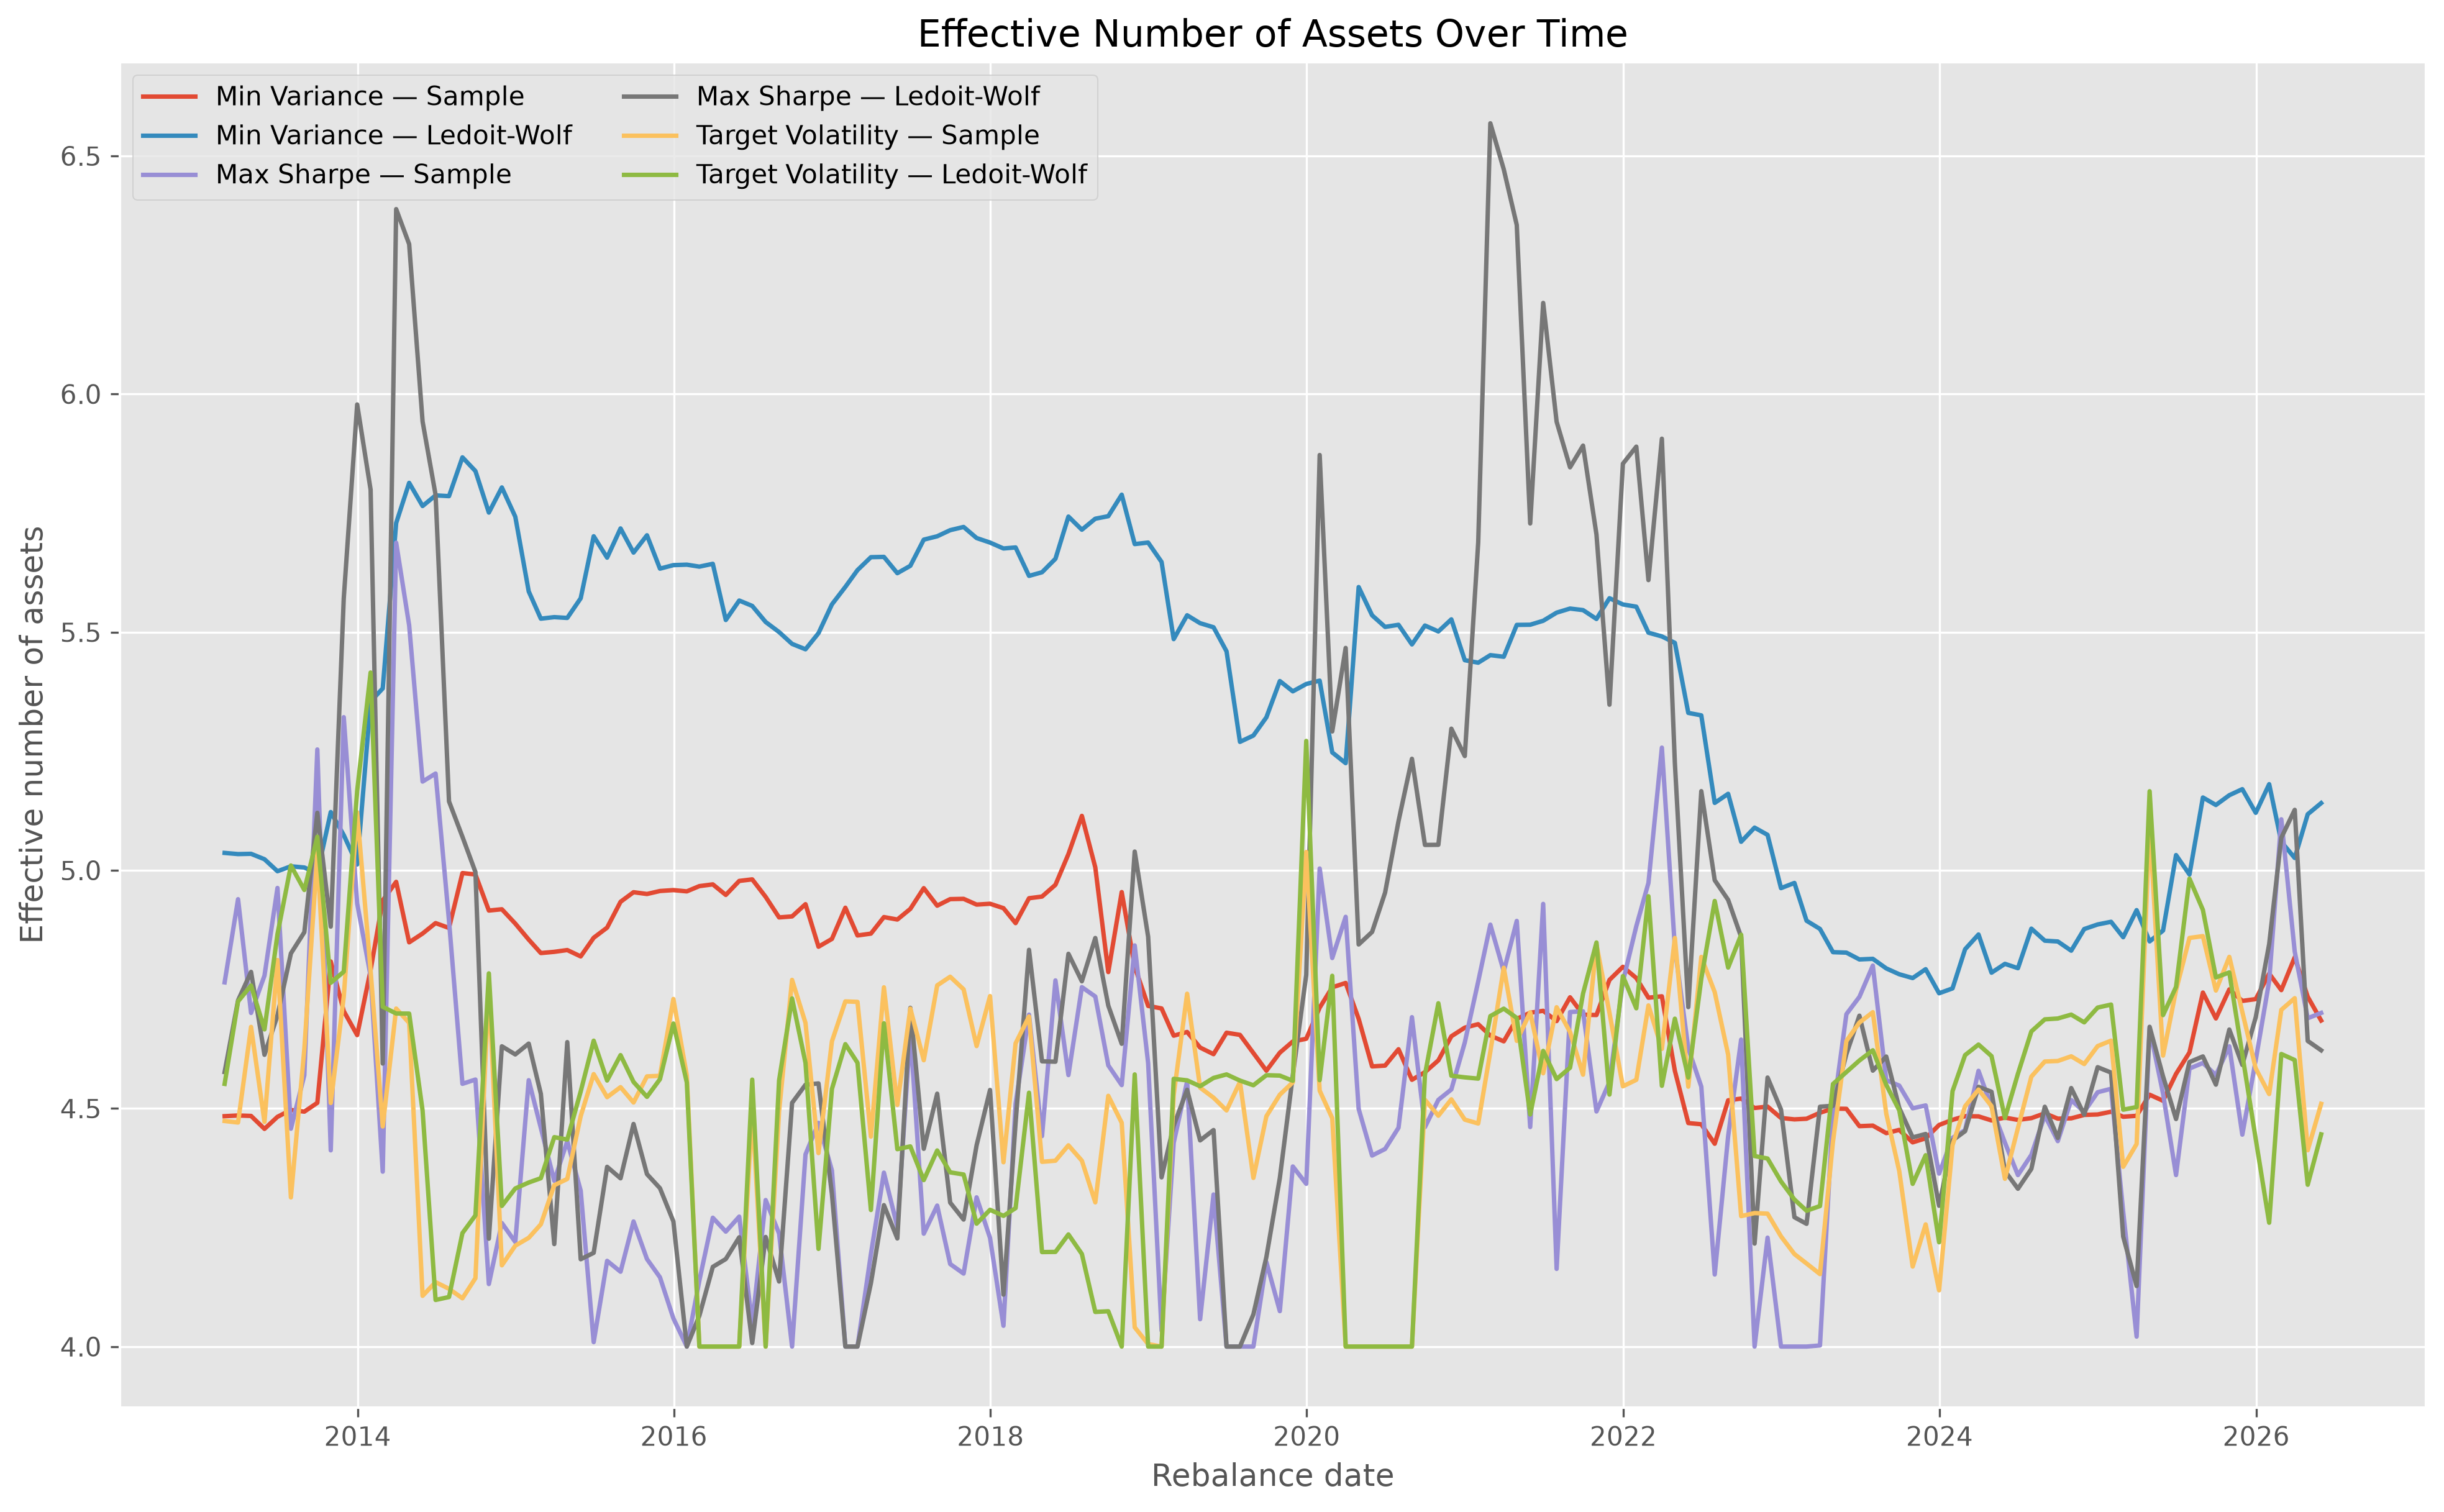

In [4]:
for filename in [
    'markowitz_weight_heatmap_min_variance.png',
    'markowitz_weight_heatmap_max_sharpe.png',
    'markowitz_weight_heatmap_target_vol.png',
    'effective_number_of_assets_over_time.png',
]:
    display(Image(filename=str(FIGURES / filename)))

## Concentration, diversification, and estimation error

The Herfindahl index, $\sum_i w_i^2$, rises as a portfolio becomes more concentrated. Its inverse is the effective number of assets. Classical mean-variance weights can react strongly to small changes in expected returns and covariances; maximum-Sharpe and target-volatility portfolios are especially exposed because their objectives directly reward higher estimated returns. The 25% cap limits single-asset concentration but does not eliminate instability or turnover.

Ledoit-Wolf shrinkage regularizes the covariance matrix and stabilizes risk estimates when the estimation window is short relative to the asset count. The final report evaluates the realized next-month performance of these saved allocations on the common core-universe period.
